# Time Series Forecasting

## Business Problem

The objective of this analysis is to forecast future taxi demand using historical trip data.

Accurate demand forecasting can help:

- Improve resource allocation
- Optimize fleet management
- Support transportation planning
- Anticipate peak demand periods

## Forecast Target

Number of taxi trips per day

In [1]:
import pandas as pd 
import numpy as np 

import matplotlib.pyplot as plt
import seaborn as sns 

from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error 
)


In [2]:
df = pd.read_csv(
    '../data/processed/NYC_cleaned.csv'
)

In [3]:
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime']
)
df.shape
df

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,pickup_year,pickup_month,pickup_day,pickup_hour,pickup_weekday
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455,2016,3,14,17,Monday
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663,2016,6,12,0,Sunday
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124,2016,1,19,11,Tuesday
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429,2016,4,6,19,Wednesday
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435,2016,3,26,13,Saturday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1447750,id2376096,2,2016-04-08 13:31:04,2016-04-08 13:44:02,4,-73.982201,40.745522,-73.994911,40.740170,N,778,2016,4,8,13,Friday
1447751,id1049543,1,2016-01-10 07:35:15,2016-01-10 07:46:10,1,-74.000946,40.747379,-73.970184,40.796547,N,655,2016,1,10,7,Sunday
1447752,id2304944,2,2016-04-22 06:57:41,2016-04-22 07:10:25,1,-73.959129,40.768799,-74.004433,40.707371,N,764,2016,4,22,6,Friday
1447753,id2714485,1,2016-01-05 15:56:26,2016-01-05 16:02:39,1,-73.982079,40.749062,-73.974632,40.757107,N,373,2016,1,5,15,Tuesday


In [4]:
daily_trips = (
    df.groupby(
    df['pickup_datetime'].dt.date
    )
    .size()
    .reset_index()
 )

daily_trips 



,pickup_datetime,0
0,2016-01-01,7100
1,2016-01-02,6460
2,2016-01-03,6298
3,2016-01-04,6670
4,2016-01-05,7146
...,...,...
177,2016-06-26,7011
178,2016-06-27,7266
179,2016-06-28,7200
180,2016-06-29,7582


In [5]:
daily_trips.columns = [
    'date',
    'trips_count'
]

daily_trips.head()

,date,trips_count
0,2016-01-01,7100
1,2016-01-02,6460
2,2016-01-03,6298
3,2016-01-04,6670
4,2016-01-05,7146


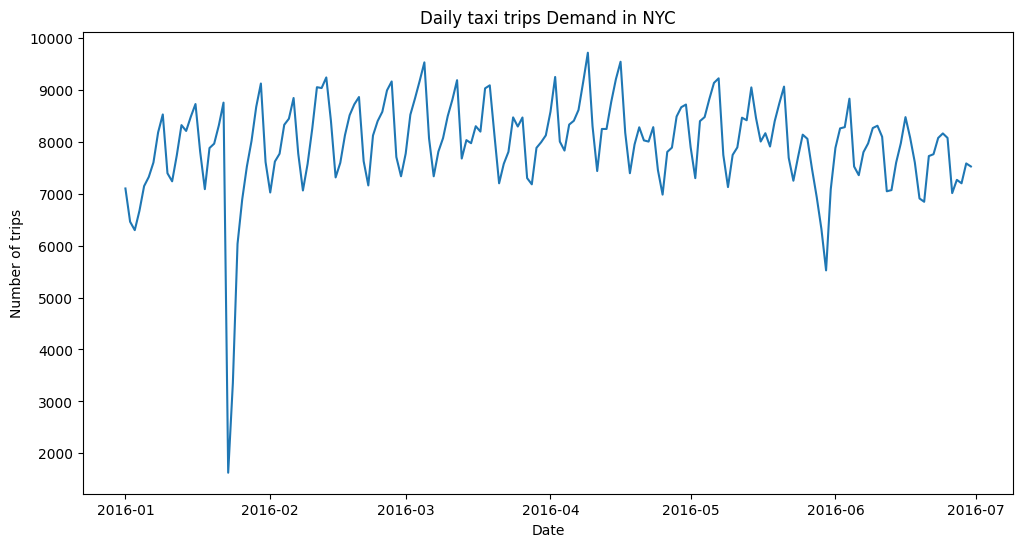

In [6]:
plt.figure(
    figsize=(12,6)
)

plt.plot(
    daily_trips['date'],
    daily_trips['trips_count']
)

plt.title(
    'Daily taxi trips Demand in NYC'
)

plt.xlabel('Date')
plt.ylabel('Number of trips')

plt.show()

## Initial Observations

The daily demand pattern shows fluctuations across time.

The time series may contain:

- Trends
- Seasonal effects
- High-demand periods
- Low-demand periods

Further analysis is required before forecasting.

In [7]:
daily_trips['moving_average'] = (
    daily_trips['trips_count']
    .rolling(window=7)
    .mean()
)

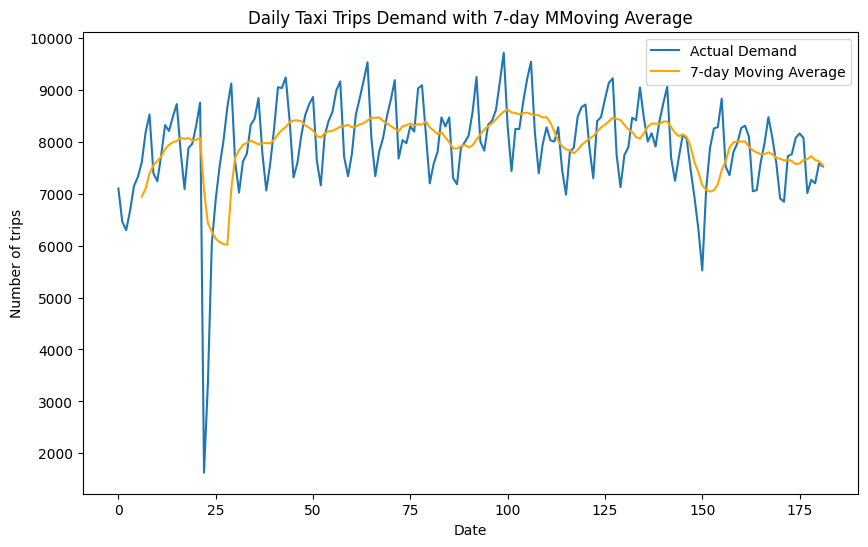

In [8]:
plt.figure(figsize=(10,6))

plt.plot(
    daily_trips['trips_count'],
    label='Actual Demand'
)

plt.plot(
    daily_trips['moving_average'],
    label='7-day Moving Average',
    color='orange'
    )

plt.title('Daily Taxi Trips Demand with 7-day MMoving Average')
plt.xlabel('Date')
plt.ylabel('Number of trips')
plt.legend()
plt.show()

# Time Series Exploration

## Key Findings

The daily taxi demand remains relatively stable throughout the observation period.

Most days record between 7,000 and 9,500 trips.

The 7-day moving average reveals recurring patterns, suggesting the presence of weekly seasonality.

A few abnormal low-demand days were identified and may correspond to exceptional events or data collection anomalies.

Overall, the time series appears suitable for forecasting.

In [9]:
train_size = int(
    len(daily_trips) * 0.8
)

train = daily_trips['trips_count'][:train_size]

test = daily_trips['trips_count'][train_size:]

In [10]:
from statsmodels.tsa.stattools import adfuller 

result = adfuller (
    daily_trips['trips_count']

)

print('AFD statistic:', result[0])
print('p-value:', result[1])


AFD statistic: -3.51615964661494
p-value: 0.007581650327815861


<Figure size 1200x600 with 0 Axes>

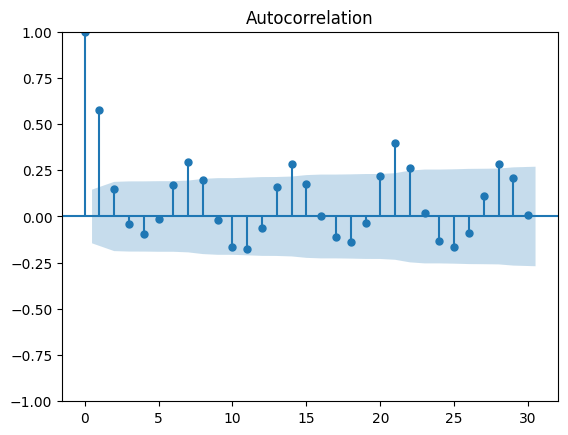

In [11]:
from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf
)

plt.figure(figsize=(12,6))

plot_acf(
    daily_trips['trips_count'],
    lags=30
)

plt.show()

<Figure size 1200x600 with 0 Axes>

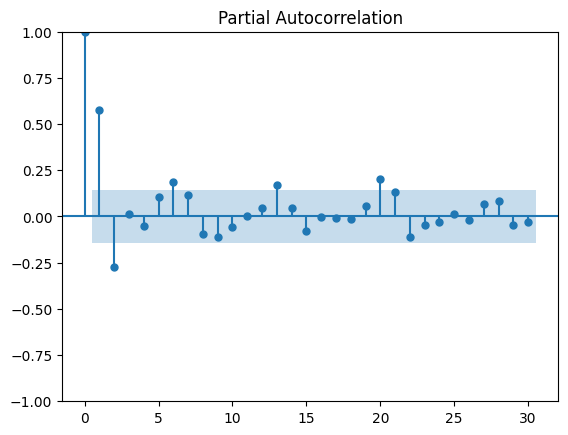

In [12]:
plt.figure(figsize=(12,6))

plot_pacf(
    daily_trips["trips_count"],
    lags=30
)

plt.show()

# Stationarity and Seasonality Assessment

## Augmented Dickey-Fuller Test

The ADF test returned a p-value below 0.05, indicating that the time series is stationary.

## Autocorrelation Analysis

The ACF plot revealed recurring peaks at lags 7, 14, 21 and 28, suggesting the presence of weekly seasonality.

## Modeling Decision

Based on the stationarity test and autocorrelation patterns, a SARIMA model was selected instead of a standard ARIMA model.

Selected Model:

SARIMA(1,0,1)(1,0,1,7)

In [13]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train,
    order=(1,0,1),
    seasonal_order=(1,0,1,7)
)

sarima_fit = sarima_model.fit(
    disp=False
)


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [14]:
forecast = sarima_fit.forecast(
    steps=len(test)
)

In [15]:
from  sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

mae = mean_absolute_error(
    test,
    forecast
)

rmse = np.sqrt(
    mean_squared_error(
        test,
        forecast
    )
)

print(F'Mean Absolute error (MAE): {mae}')
print(f'Root Mean Squared Error (RMSE): {rmse}')

Mean Absolute error (MAE): 352.471121876988
Root Mean Squared Error (RMSE): 523.1268840665754


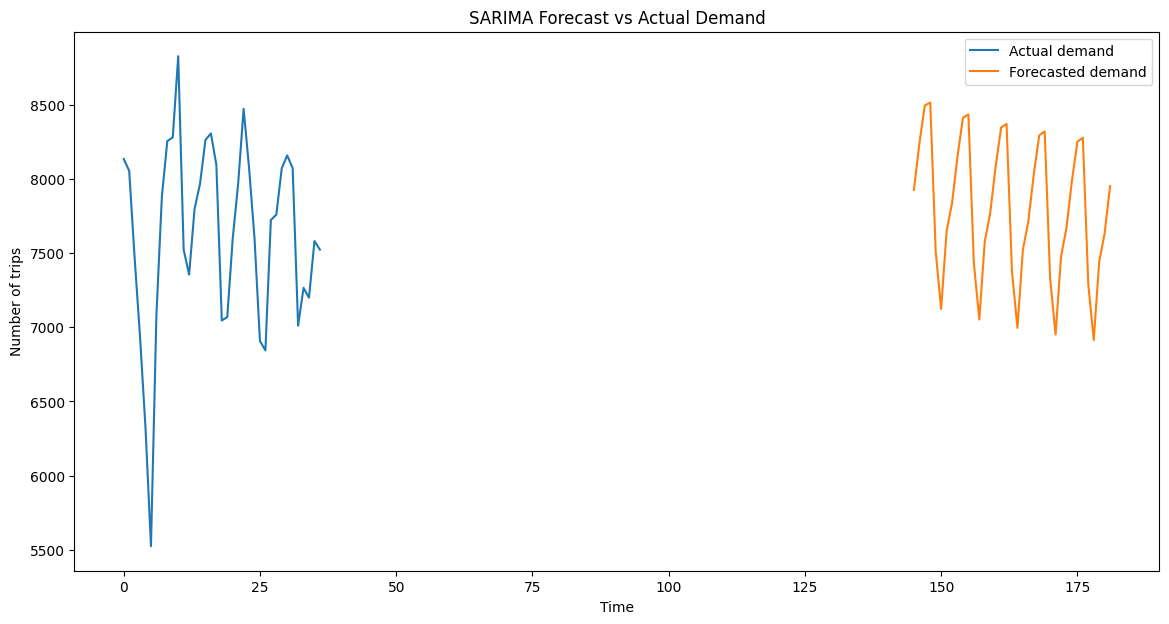

In [16]:
plt.figure(figsize=(14,7))

plt.plot(
    test.values,
    label='Actual demand'

)

plt.plot(
    forecast,
    label='Forecasted demand'
)

plt.legend()

plt.title('SARIMA Forecast vs Actual Demand')

plt.xlabel('Time')
plt.ylabel('Number of trips')

plt.show()


In [18]:
plt.savefig(
    "../assets/sarima_forecast.png",
    bbox_inches="tight"
)


<Figure size 640x480 with 0 Axes>

In [17]:
future_forecast = sarima_fit.forecast(
    steps=7
)

print(f'Forecasted demand forthe next 7 day is : {future_forecast}')

Forecasted demand forthe next 7 day is : 145    7926.573972
146    8238.470550
147    8496.067846
148    8516.470555
149    7509.806333
150    7123.836808
151    7648.585607
Name: predicted_mean, dtype: float64


# Time Series Forecasting Conclusion

A SARIMA model was developed to forecast future taxi demand.

The stationarity test confirmed that the time series was suitable for forecasting.

Autocorrelation analysis revealed a weekly seasonal pattern, leading to the selection of a SARIMA model with a seasonal period of 7 days.

Model Performance:

- MAE: 352.47 trips
- RMSE: 523.13 trips

The model successfully captured recurring demand patterns and generated realistic forecasts for the next seven days.

These results demonstrate the potential of time series forecasting for transportation planning and resource optimization.